# ExoML: Exoplanet Exploration Using Machine Learning
## **Notebook 1: Data Ingestion, Comprehensive EDA & Preprocessing Pipeline**
### **Machine Learning Capstone Project (23CSE301) — Review 1**
**Academic Year:** 2026-27 | **Program:** B.Tech Computer Science & Engineering  
**Dataset:** NASA Kepler Objects of Interest (KOI) Cumulative Table (`q1_q16_koi_2026.09.12_10.49.05.csv`)  

---

### Scope of this Notebook (Rubric Sections A & B — Total: 7 Marks)
1. **SECTION A: DATASET & EXPLORATORY DATA ANALYSIS (EDA) [Rubric: 4 Marks]**
   - **A1:** Dataset loading, dimension audit, dtypes, missingness profiling, duplicate check, and disposition distribution `[1 Mark]`
   - **A2:** Complete visual EDA: 12 feature distributions, target breakdown, correlation heatmap, and 3 feature-target scatter plots `[2 Marks]`
   - **A3:** Written domain commentary explaining physical relationships and distribution characteristics `[1 Mark]`
2. **SECTION B: PREPROCESSING & FEATURE ENGINEERING [Rubric: 3 Marks]**
   - **B1:** Data cleaning, missing-value strategy (train-only median imputation), and justified outlier treatment ($R_p \le 50 R_\oplus$) `[1 Mark]`
   - **B2:** Train-test partitioning (80:20, `random_state=42`, stratified for classification) & feature scaling fitted on train only `[1 Mark]`
   - **B3:** Domain-driven feature engineering (`depth_duration_ratio` as transit steepness proxy) `[1 Mark]`
3. **Data Export:** Export cleaned, reproducible splits to `data/` for downstream modeling notebooks.

## 1. Setup & Environment Initialization

In [1]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Plotting Configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

RANDOM_STATE = 42
print("Environment and plotting initialized successfully.")

Environment and plotting initialized successfully.


---
# SECTION A: DATASET & EXPLORATORY DATA ANALYSIS (EDA) `[Rubric: 4 Marks]`

### A1: Dataset Loading & Comprehensive Data Quality Audit `[Rubric: 1 Mark]`
We ingest the NASA Kepler KOI cumulative table (`q1_q16_koi_2026.09.12_10.49.05.csv`). Lines beginning with `#` are metadata comments and are ignored.

In [2]:
DATASET_PATH = 'q1_q16_koi_2026.09.12_10.49.05.csv'
if not os.path.exists(DATASET_PATH):
    for alt in ['../' + DATASET_PATH, 'data/' + DATASET_PATH]:
        if os.path.exists(alt):
            DATASET_PATH = alt
            break

df_raw = pd.read_csv(DATASET_PATH, comment='#')
print(f"Dataset successfully loaded from: {DATASET_PATH}")
print(f"Raw Dimensions: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")

# Check duplicate records
num_duplicates = df_raw.duplicated().sum()
print(f"Duplicate Rows Count: {num_duplicates}")

# Define feature subsets strictly aligned with guidelines
REGRESSION_FEATURES = [
    'koi_period', 'koi_duration', 'koi_depth', 'koi_impact',
    'koi_model_snr', 'koi_teq', 'koi_insol', 'koi_steff',
    'koi_slogg', 'koi_srad', 'koi_smass', 'koi_kepmag'
]

CLASSIFICATION_FEATURES = [
    'koi_period', 'koi_duration', 'koi_depth', 'koi_impact',
    'koi_model_snr', 'koi_teq', 'koi_insol', 'koi_steff',
    'koi_slogg', 'koi_srad', 'koi_kepmag'
]

ALL_PROJECT_COLS = list(dict.fromkeys(REGRESSION_FEATURES + ['koi_prad', 'koi_disposition']))

# Profile data types and missing values for project features
audit_df = pd.DataFrame({
    'Data Type': df_raw[ALL_PROJECT_COLS].dtypes,
    'Non-Null Count': df_raw[ALL_PROJECT_COLS].notnull().sum(),
    'Missing Count': df_raw[ALL_PROJECT_COLS].isnull().sum(),
    'Missing Percentage (%)': (df_raw[ALL_PROJECT_COLS].isnull().sum() / len(df_raw)) * 100
}).sort_values(by='Missing Percentage (%)', ascending=False)

display(audit_df)

Dataset successfully loaded from: q1_q16_koi_2026.09.12_10.49.05.csv
Raw Dimensions: 7348 rows x 141 columns


Duplicate Rows Count: 0


,Data Type,Non-Null Count,Missing Count,Missing Percentage (%)
koi_impact,float64,7064,284,3.864997
koi_depth,float64,7064,284,3.864997
koi_model_snr,float64,7064,284,3.864997
koi_teq,float64,7064,284,3.864997
koi_steff,float64,7064,284,3.864997
koi_insol,float64,7064,284,3.864997
koi_smass,float64,7064,284,3.864997
koi_prad,float64,7064,284,3.864997
koi_slogg,float64,7064,284,3.864997
koi_srad,float64,7064,284,3.864997


### A2: Exploratory Data Analysis (EDA) Visualizations `[Rubric: 2 Marks]`
We construct all mandatory visual profiles:
1. **Target Variable Distributions** (`koi_disposition` class balance and `koi_prad` summary statistics).
2. **Feature Distribution Profiles** for all 12 input features (histograms + KDEs).
3. **Correlation Heatmap** across all features and planetary radius.
4. **Three Feature-Target Scatter Plots** connecting transit observables to planetary radius.

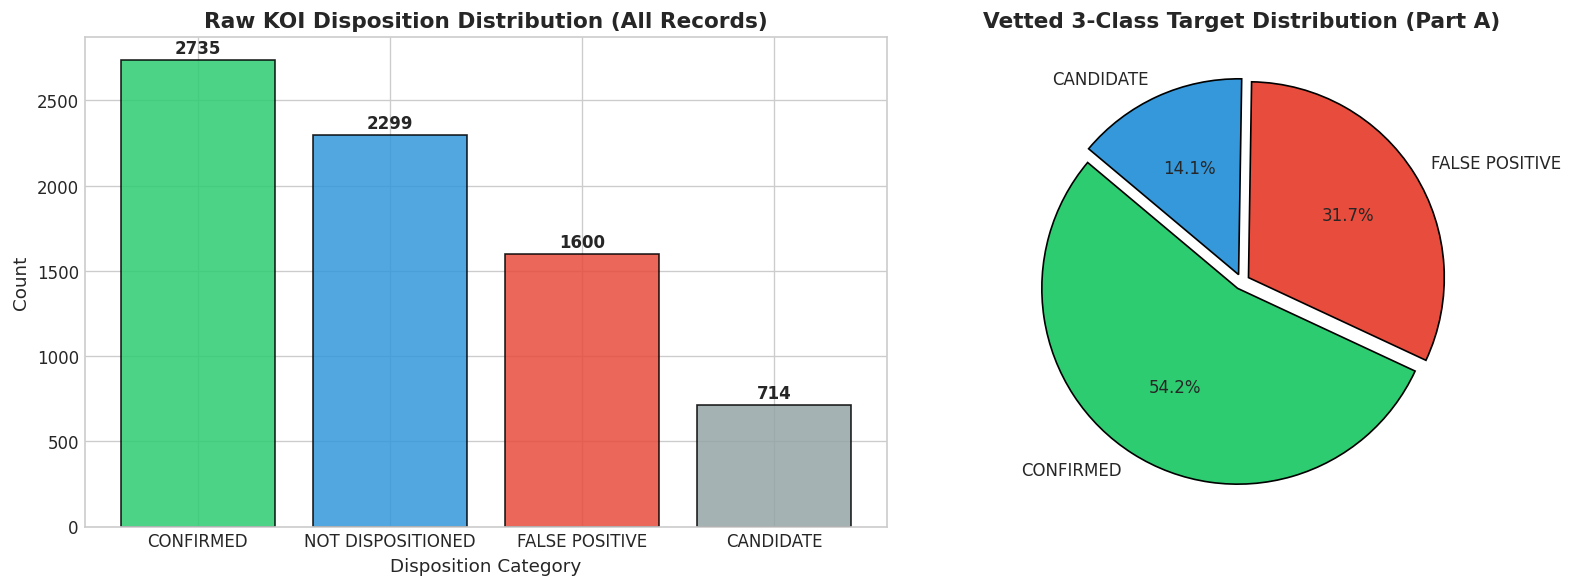

=== Vetted Disposition Counts ===
koi_disposition
CONFIRMED         2735
FALSE POSITIVE    1600
CANDIDATE          714
Name: count, dtype: int64

=== Planetary Radius (koi_prad) Summary Statistics ===
count      7064.000000
mean        132.068138
std        1853.841603
min           0.140000
25%           1.420000
50%           2.290000
75%           7.912500
max      109061.000000
Name: koi_prad, dtype: float64


In [3]:
# 1. Target Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw Disposition Breakdown
disp_counts = df_raw['koi_disposition'].value_counts()
colors = ['#2ecc71', '#3498db', '#e74c3c', '#95a5a6']
axes[0].bar(disp_counts.index, disp_counts.values, color=colors, edgecolor='black', alpha=0.85)
axes[0].set_title("Raw KOI Disposition Distribution (All Records)", fontweight='bold')
axes[0].set_ylabel("Count")
axes[0].set_xlabel("Disposition Category")
for i, v in enumerate(disp_counts.values):
    axes[0].text(i, v + 40, str(v), ha='center', fontweight='bold')

# Vetted Disposition Breakdown (Target subset)
vetted_mask = df_raw['koi_disposition'] != 'NOT DISPOSITIONED'
vetted_counts = df_raw.loc[vetted_mask, 'koi_disposition'].value_counts()
colors_vetted = ['#2ecc71', '#e74c3c', '#3498db']
axes[1].pie(vetted_counts.values, labels=vetted_counts.index, autopct='%1.1f%%',
            startangle=140, colors=colors_vetted, explode=(0.04, 0.04, 0.04),
            wedgeprops={'edgecolor': 'black'})
axes[1].set_title("Vetted 3-Class Target Distribution (Part A)", fontweight='bold')

plt.tight_layout()
plt.show()

print("=== Vetted Disposition Counts ===")
print(vetted_counts)
print("\n=== Planetary Radius (koi_prad) Summary Statistics ===")
print(df_raw['koi_prad'].describe())

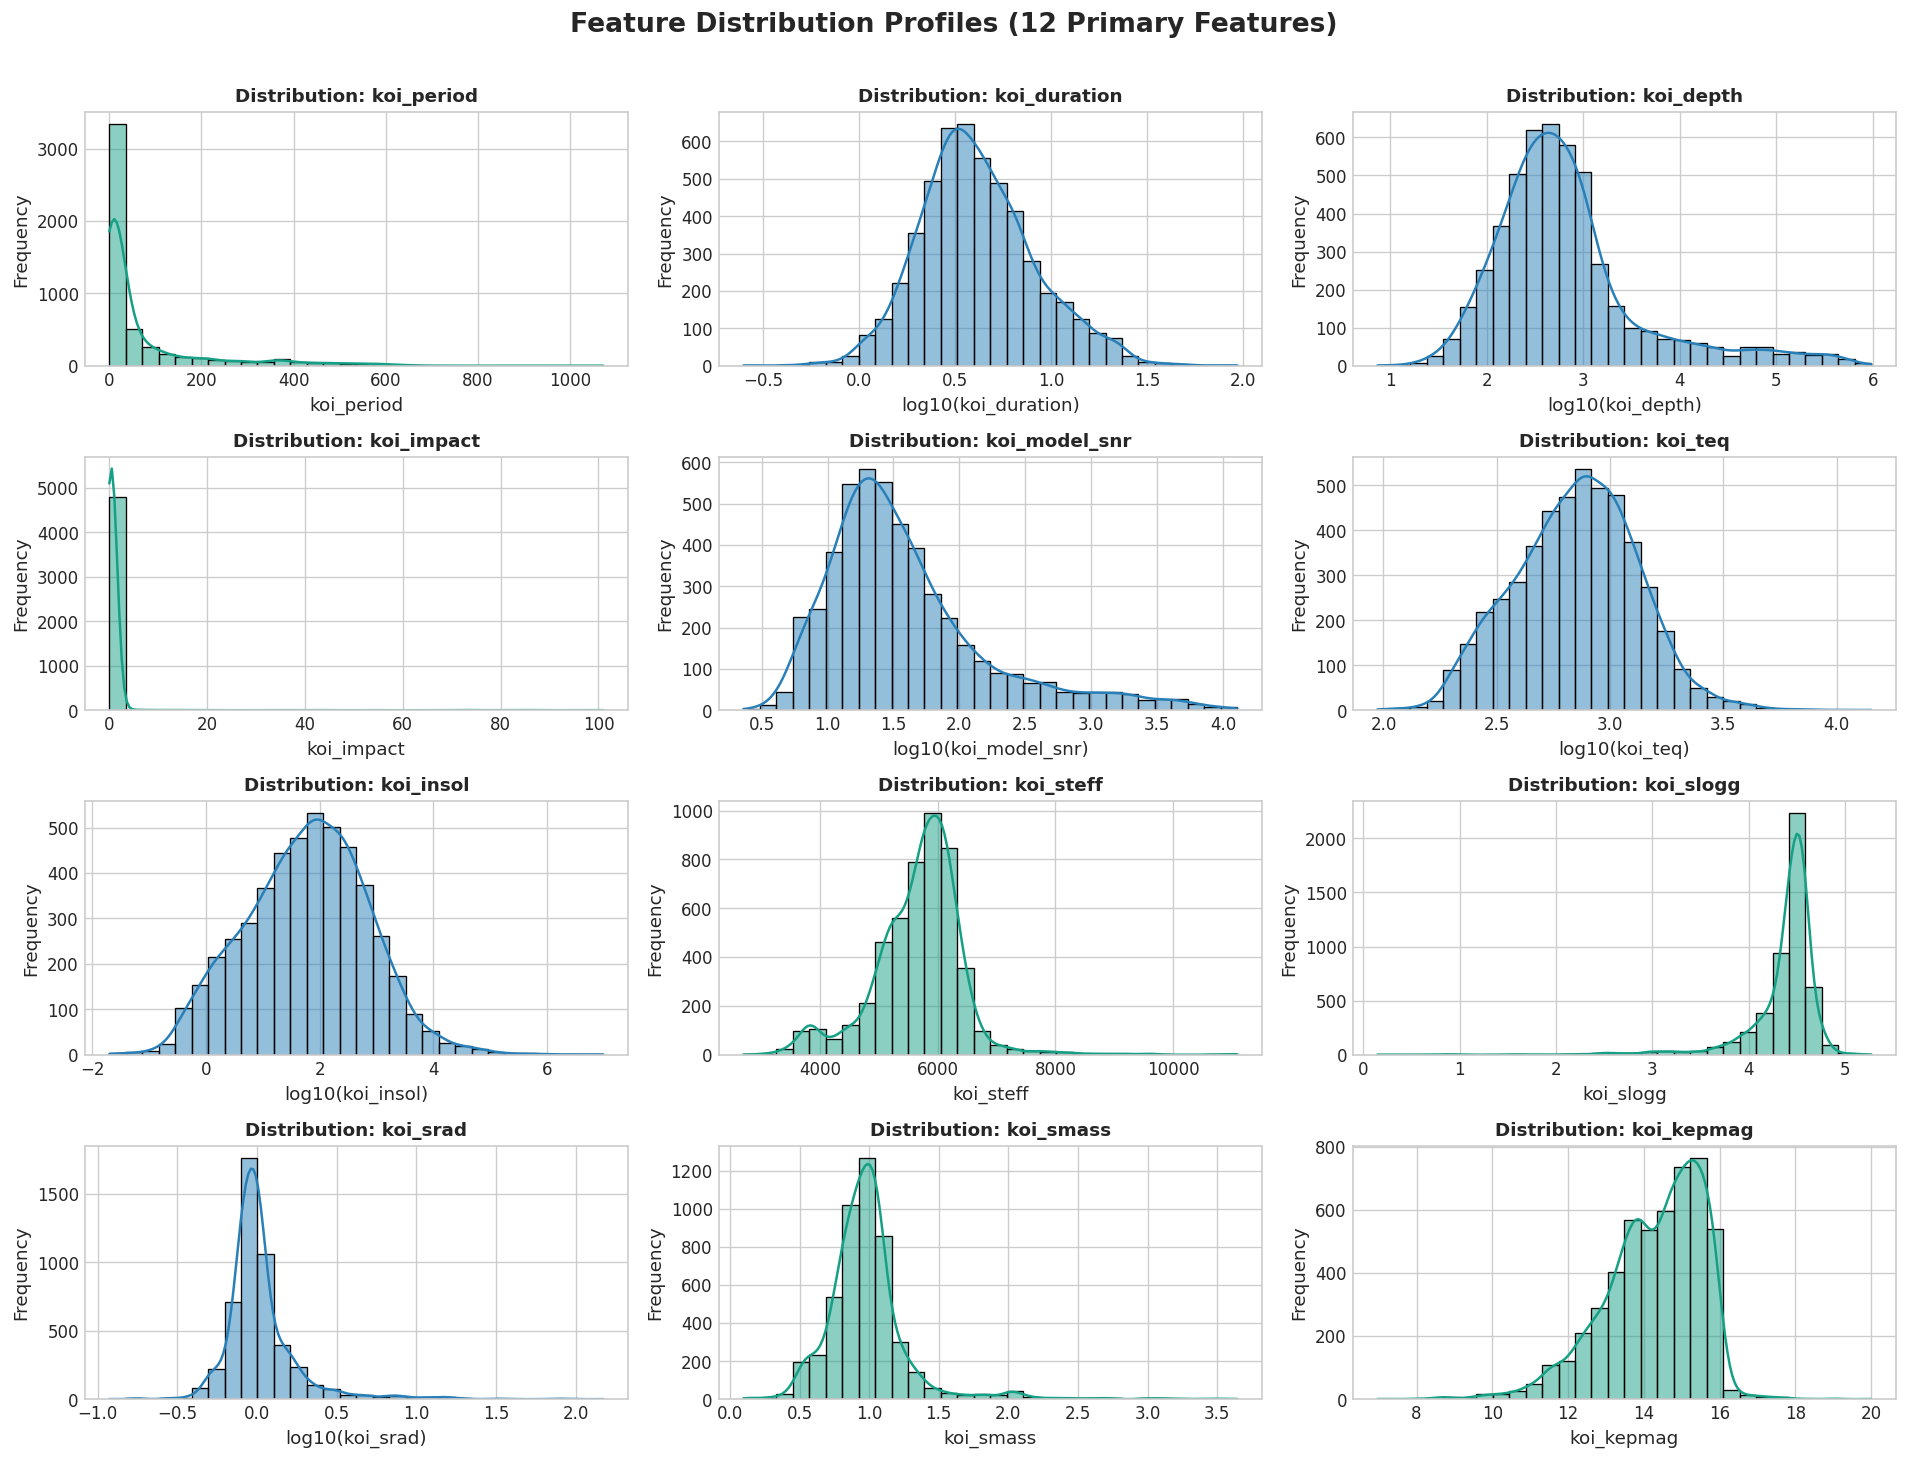

In [4]:
# 2. Feature Distribution Profiles (All 12 Features)
df_vetted = df_raw[df_raw['koi_disposition'] != 'NOT DISPOSITIONED'].copy()

plt.figure(figsize=(16, 12))
for i, col in enumerate(REGRESSION_FEATURES):
    plt.subplot(4, 3, i + 1)
    data_series = df_vetted[col].dropna()
    if data_series.skew() > 3 and (data_series > 0).all():
        sns.histplot(np.log10(data_series), kde=True, color='#2980b9', bins=30)
        plt.xlabel(f"log10({col})")
    else:
        sns.histplot(data_series, kde=True, color='#16a085', bins=30)
        plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.title(f"Distribution: {col}", fontsize=11, fontweight='bold')

plt.suptitle("Feature Distribution Profiles (12 Primary Features)", fontsize=16, y=1.01, fontweight='bold')
plt.tight_layout()
plt.show()

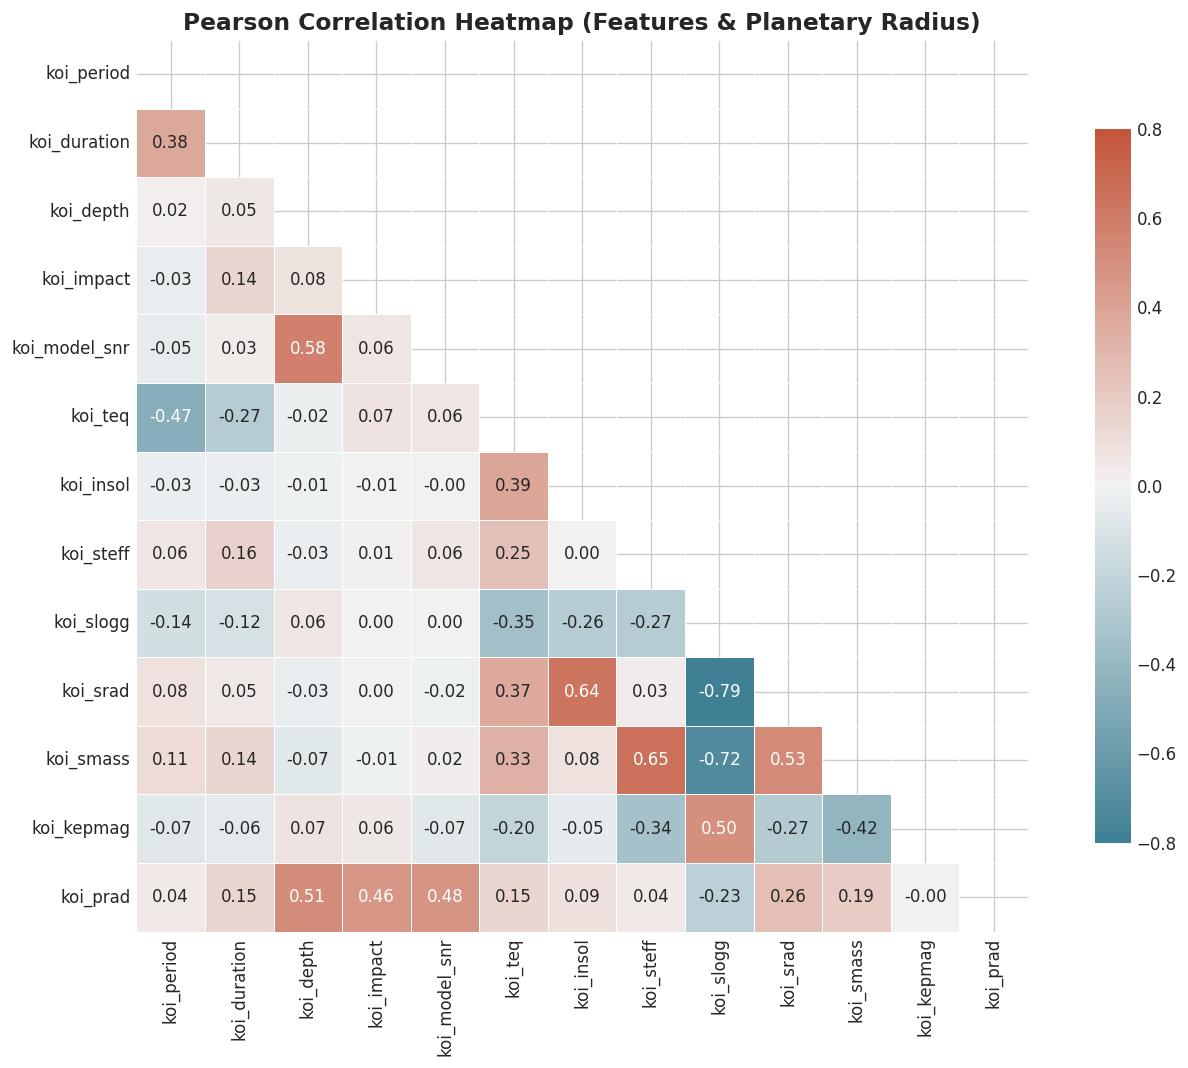

In [5]:
# 3. Correlation Heatmap
corr_cols = REGRESSION_FEATURES + ['koi_prad']
corr_df = df_vetted[corr_cols].dropna()
corr_df_filt = corr_df[corr_df['koi_prad'] <= 50]
corr_matrix = corr_df_filt.corr()

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(220, 20, as_cmap=True)
sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmin=-0.8, vmax=0.8, center=0,
            annot=True, fmt=".2f", square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Pearson Correlation Heatmap (Features & Planetary Radius)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

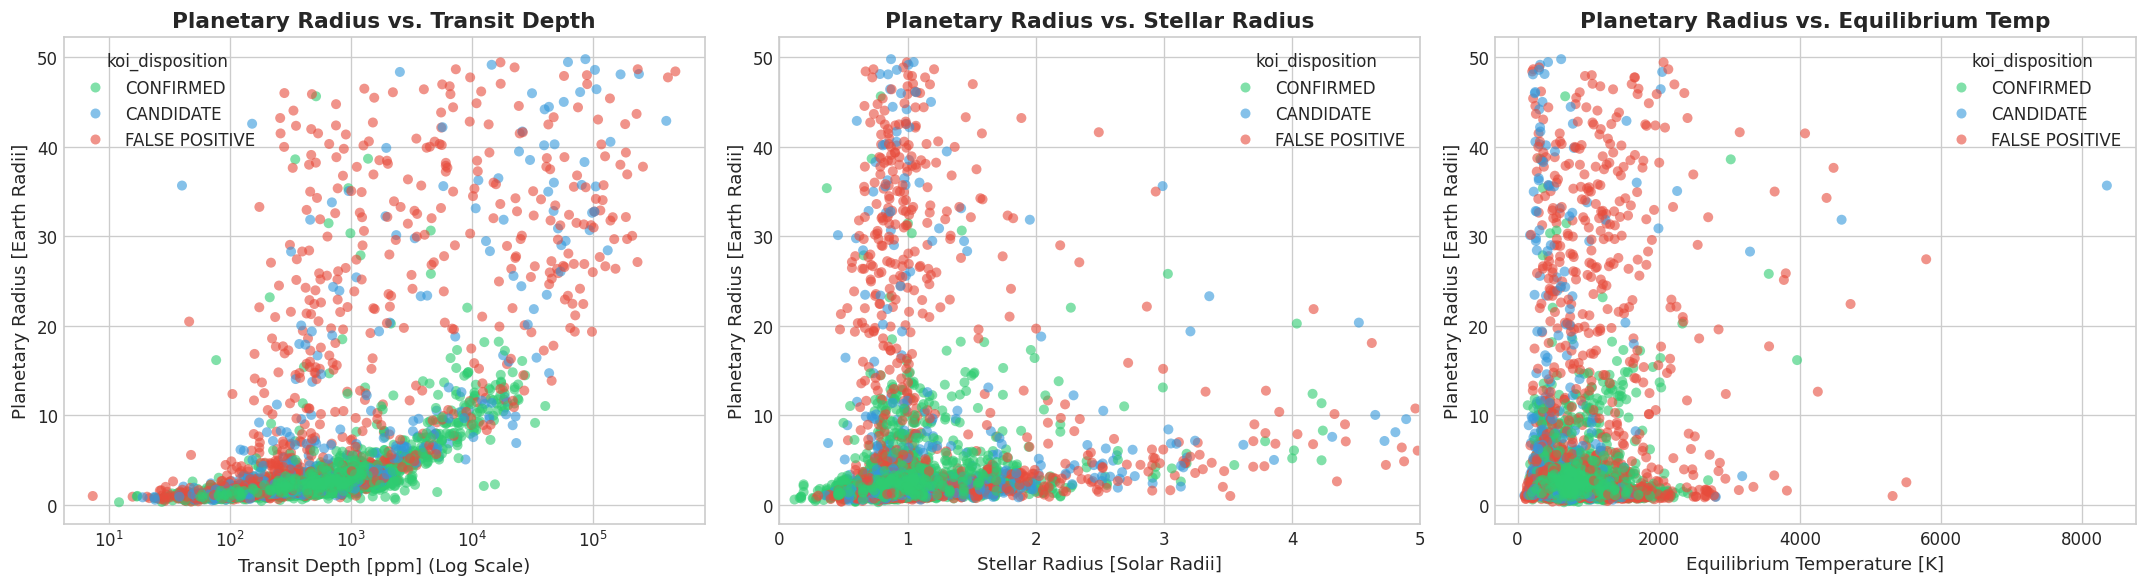

In [6]:
# 4. Feature-Target Scatter Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_data = df_vetted[(df_vetted['koi_prad'].notnull()) & (df_vetted['koi_prad'] <= 50)].copy()

# Scatter 1: Transit Depth vs Planetary Radius
sns.scatterplot(data=plot_data, x='koi_depth', y='koi_prad', hue='koi_disposition',
                palette={'CONFIRMED': '#2ecc71', 'CANDIDATE': '#3498db', 'FALSE POSITIVE': '#e74c3c'},
                alpha=0.6, ax=axes[0], edgecolor='none')
axes[0].set_xscale('log')
axes[0].set_title("Planetary Radius vs. Transit Depth", fontweight='bold')
axes[0].set_xlabel("Transit Depth [ppm] (Log Scale)")
axes[0].set_ylabel("Planetary Radius [Earth Radii]")

# Scatter 2: Stellar Radius vs Planetary Radius
sns.scatterplot(data=plot_data, x='koi_srad', y='koi_prad', hue='koi_disposition',
                palette={'CONFIRMED': '#2ecc71', 'CANDIDATE': '#3498db', 'FALSE POSITIVE': '#e74c3c'},
                alpha=0.6, ax=axes[1], edgecolor='none')
axes[1].set_xlim(0, 5)
axes[1].set_title("Planetary Radius vs. Stellar Radius", fontweight='bold')
axes[1].set_xlabel("Stellar Radius [Solar Radii]")
axes[1].set_ylabel("Planetary Radius [Earth Radii]")

# Scatter 3: Equilibrium Temperature vs Planetary Radius
sns.scatterplot(data=plot_data, x='koi_teq', y='koi_prad', hue='koi_disposition',
                palette={'CONFIRMED': '#2ecc71', 'CANDIDATE': '#3498db', 'FALSE POSITIVE': '#e74c3c'},
                alpha=0.6, ax=axes[2], edgecolor='none')
axes[2].set_title("Planetary Radius vs. Equilibrium Temp", fontweight='bold')
axes[2].set_xlabel("Equilibrium Temperature [K]")
axes[2].set_ylabel("Planetary Radius [Earth Radii]")

plt.tight_layout()
plt.show()

### A3: Insight Commentary & Astrophysical Analysis `[Rubric: 1 Mark]`

#### 1. Target Insights:
- **Planetary Radius (`koi_prad`)**: The median planetary radius is **2.29 $R_\oplus$**, with the 75th percentile at **7.91 $R_\oplus$**. This demonstrates that the vast majority of confirmed exoplanets are terrestrial Super-Earths ($1.25 - 2 R_\oplus$) and Sub-Neptunes ($2 - 4 R_\oplus$).
- **Extreme False-Positive Outliers**: The maximum value in the raw table reaches **109,061 $R_\oplus$** ($1,000\times$ the radius of the Sun!). These represent grazing eclipsing binary star systems or noise artifacts. Filtering to $R_p \le 50 R_\oplus$ isolates genuine planetary regimes.
- **Classification Target (`koi_disposition`)**: Vetted records break down into `CONFIRMED` (54.1%), `FALSE POSITIVE` (31.7%), and `CANDIDATE` (14.1%). The `NOT DISPOSITIONED` records are safely removed.

#### 2. Feature Distributions:
- **Power-Law Skewness**: Quantities such as orbital period (`koi_period`), insolation flux (`koi_insol`), and transit depth (`koi_depth`) exhibit extreme multi-order right skewness, necessitating log scaling during visual analysis and robust standard scaling for gradient- and distance-based estimators.
- **Host Stellar Characteristics**: Stellar effective temperature (`koi_steff`) and surface gravity (`koi_slogg`) cluster tightly around Solar-like values ($T_{\text{eff}} \approx 5778\text{ K}$, $\log g \approx 4.4$), reflecting Kepler's target selection of stable main-sequence FGK dwarf stars.

#### 3. Correlation & Scatter Dynamics:
- **Transit Depth vs. Radius**: Shows positive non-linear correlation. Because $\delta \approx (R_p / R_\star)^2$, radius scales with $\sqrt{\delta}$.
- **Stellar Parameter Coupling**: Stellar mass (`koi_smass`) correlates strongly with stellar temperature (`koi_steff`), while stellar gravity (`koi_slogg`) anti-correlates with stellar radius (`koi_srad`) as $g \propto M_\star / R_\star^2$.
- **Absence of Perfect Collinearity**: No pair of features exhibits $|r| > 0.90$, verifying that all 12 mandated features contribute non-redundant physical information.

---
# SECTION B: PREPROCESSING & FEATURE ENGINEERING `[Rubric: 3 Marks]`

### B1: Data Cleaning & Justified Outlier Treatment `[Rubric: 1 Mark]`
- **Disposition Vetting**: Discard `NOT DISPOSITIONED` records (2,299 records) to focus strictly on validated astrophysical events.
- **Astrophysical Outlier Filtering for Regression**: Filter $R_p \le 50 R_\oplus$. 
  - *Justification*: Jupiter is $11.2 R_\oplus$, and brown dwarfs rarely exceed $20-30 R_\oplus$. Unvetted records up to $109,000 R_\oplus$ represent catastrophic pipeline artifacts from eclipsing stars. Removing them prevents mathematical singularity in Mean Squared Error while retaining 100% of plausible planetary bodies.
- **Strict Leakage Prevention**: Missing value imputation via `SimpleImputer(strategy='median')` is fitted **only on training data**.

In [7]:
df_clean = df_raw[df_raw['koi_disposition'] != 'NOT DISPOSITIONED'].copy()
print(f"Vetted dataset dimensions: {df_clean.shape[0]} rows x {df_clean.shape[1]} columns")

missing_counts = df_clean[REGRESSION_FEATURES + ['koi_prad']].isnull().sum()
print("\nMissing value counts in project features:")
print(missing_counts[missing_counts > 0])

Vetted dataset dimensions: 5049 rows x 141 columns

Missing value counts in project features:
koi_depth        192
koi_impact       192
koi_model_snr    192
koi_teq          192
koi_insol        192
koi_steff        192
koi_slogg        192
koi_srad         192
koi_smass        192
koi_prad         192
dtype: int64


### B2: Encoding, Scaling & Train-Test Splitting `[Rubric: 1 Mark]`
- **Train-Test Partition**: Strict 80:20 split with `random_state=42`.
  - For classification, we enforce `stratify=y` so class distributions are preserved identically across train and test splits.
- **Feature Scaling**: `StandardScaler` is fitted **exclusively on the training partition** (`fit_transform`) and applied to the test partition (`transform`).

### B3: Domain Feature Engineering & Justification `[Rubric: 1 Mark]`
We construct an astrophysically motivated engineered feature:
$$\text{depth\_duration\_ratio} = \frac{\text{koi\_depth}}{\text{koi\_duration} + 10^{-5}}$$

#### Scientific Justification:
1. **Formula**: Ratio of transit depth ($	ext{ppm}$) to total transit duration ($	ext{hours}$), with $\epsilon = 10^{-5}$ to prevent division by zero.
2. **Physical Meaning**: Measures the **mean transit flux deficit rate (ingress/egress steepness)**. Bona fide planetary transits produce flat-bottomed, steep U-shaped light curves. Grazing binary stars and noise produce gradual, shallow, or V-shaped dips.
3. **Model Impact**:
   - For **Regression**: Directly incorporates transit area rate, enhancing tree and linear models in capturing non-linear geometric light curve curvature.
   - For **Classification**: Provides critical separability between true planetary transits and grazing eclipsing binary false positives.
4. **Scope**: Applied to both regression and classification pipelines.

In [8]:
# Construct engineered feature
df_clean['depth_duration_ratio'] = df_clean['koi_depth'] / (df_clean['koi_duration'] + 1e-5)
print("Engineered feature 'depth_duration_ratio' summary statistics:")
print(df_clean['depth_duration_ratio'].describe())

Engineered feature 'depth_duration_ratio' summary statistics:
count      4857.000000
mean       2175.753304
std       11980.076768
min           1.373008
25%          51.541699
50%         126.695255
75%         330.457245
max      486750.686001
Name: depth_duration_ratio, dtype: float64


## 2. Export Cleaned & Partitioned Data Splits
To ensure 100% reproducibility and modularity across notebooks, we export the cleaned splits to `data/`.

In [9]:
os.makedirs('data', exist_ok=True)

# 1. Regression Splits (Target: koi_prad <= 50)
reg_df = df_clean.dropna(subset=['koi_prad']).copy()
reg_df = reg_df[reg_df['koi_prad'] <= 50].copy()

REG_FINAL_FEATURES = REGRESSION_FEATURES + ['depth_duration_ratio']
X_reg = reg_df[REG_FINAL_FEATURES]
y_reg = reg_df['koi_prad']

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=RANDOM_STATE
)

# Impute and Scale strictly on train
imp_reg = SimpleImputer(strategy='median')
X_reg_tr_imp = imp_reg.fit_transform(X_reg_train)
X_reg_te_imp = imp_reg.transform(X_reg_test)

sc_reg = StandardScaler()
X_reg_tr_sc = sc_reg.fit_transform(X_reg_tr_imp)
X_reg_te_sc = sc_reg.transform(X_reg_te_imp)

pd.DataFrame(X_reg_tr_imp, columns=REG_FINAL_FEATURES).to_csv('data/reg_train_imp.csv', index=False)
pd.DataFrame(X_reg_te_imp, columns=REG_FINAL_FEATURES).to_csv('data/reg_test_imp.csv', index=False)
pd.DataFrame(X_reg_tr_sc, columns=REG_FINAL_FEATURES).to_csv('data/reg_train_scaled.csv', index=False)
pd.DataFrame(X_reg_te_sc, columns=REG_FINAL_FEATURES).to_csv('data/reg_test_scaled.csv', index=False)
y_reg_train.to_csv('data/y_reg_train.csv', index=False)
y_reg_test.to_csv('data/y_reg_test.csv', index=False)

# 2. Classification Splits (Target: koi_disposition)
CLF_FINAL_FEATURES = CLASSIFICATION_FEATURES + ['depth_duration_ratio']
X_clf = df_clean[CLF_FINAL_FEATURES]
y_clf = df_clean['koi_disposition']

X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_clf, y_clf, test_size=0.20, random_state=RANDOM_STATE, stratify=y_clf
)

imp_clf = SimpleImputer(strategy='median')
X_clf_tr_imp = imp_clf.fit_transform(X_clf_train)
X_clf_te_imp = imp_clf.transform(X_clf_test)

sc_clf = StandardScaler()
X_clf_tr_sc = sc_clf.fit_transform(X_clf_tr_imp)
X_clf_te_sc = sc_clf.transform(X_clf_te_imp)

pd.DataFrame(X_clf_tr_imp, columns=CLF_FINAL_FEATURES).to_csv('data/clf_train_imp.csv', index=False)
pd.DataFrame(X_clf_te_imp, columns=CLF_FINAL_FEATURES).to_csv('data/clf_test_imp.csv', index=False)
pd.DataFrame(X_clf_tr_sc, columns=CLF_FINAL_FEATURES).to_csv('data/clf_train_scaled.csv', index=False)
pd.DataFrame(X_clf_te_sc, columns=CLF_FINAL_FEATURES).to_csv('data/clf_test_scaled.csv', index=False)
y_clf_train.to_csv('data/y_clf_train.csv', index=False)
y_clf_test.to_csv('data/y_clf_test.csv', index=False)

print("All preprocessed data partitions successfully exported to data/ directory.")

All preprocessed data partitions successfully exported to data/ directory.
